In [38]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [39]:
from sklearn.model_selection import train_test_split as tts
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [40]:
X = 6*np.random.rand(200,1)-3
y = 0.8*X**2 +0.9*X + 2 + np.random.randn(200,1)

The equation above was y = 0.8x^2 + 0.9x +2

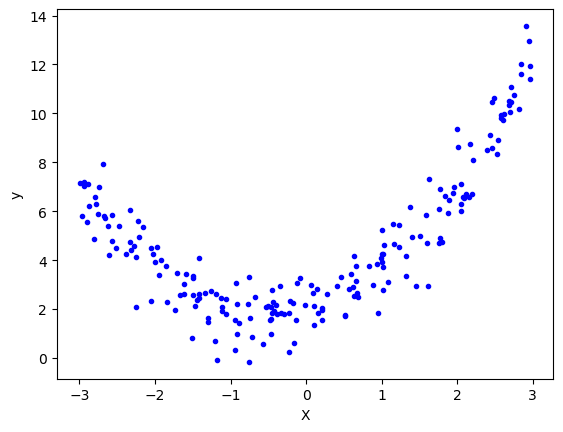

In [41]:
plt.plot(X,y,'b.')
plt.xlabel("X")
plt.ylabel('y')
plt.show()


In [42]:
lr = LinearRegression()

In [43]:
X_train, X_test, y_train, y_test = tts(X,y, test_size=0.2, 
                                       random_state=2)

In [44]:
lr.fit(X_train, y_train)

LinearRegression()

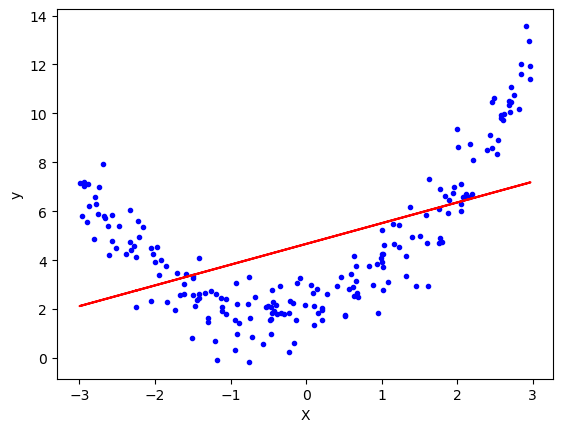

In [45]:
plt.plot(X,y,'b.')
plt.xlabel("X")
plt.ylabel('y')
plt.plot(X, lr.predict(X), color = 'red')
plt.show()

In [46]:
y_pred = lr.predict(X_test)

In [47]:
r2_score(y_test, y_pred)

0.2488520342788596

In [48]:
poly = PolynomialFeatures(degree=2)
X_train_trans = poly.fit_transform(X_train)
X_test_trans = poly.fit_transform(X_test)

In [49]:
X_train[0]

array([-0.21996787])

In [50]:
X_train_trans[0]

array([ 1.        , -0.21996787,  0.04838586])

In [51]:
lr = LinearRegression()

In [52]:
lr.fit(X_train_trans, y_train)

LinearRegression()

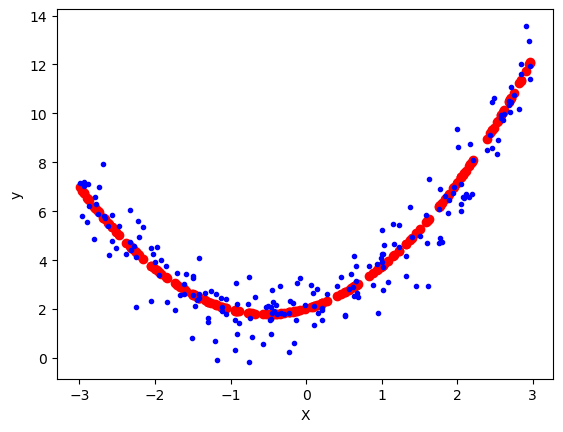

In [53]:
plt.plot(X,y,'b.')
plt.xlabel("X")
plt.ylabel('y')
plt.scatter(X, lr.predict(poly.transform(X)), color = 'red')
plt.show()

In [54]:
X.shape

(200, 1)

In [60]:
y_pred = lr.predict(X_test_trans)

In [62]:
r2_score(y_test, y_pred)*100

86.47197583367452

In [63]:
lr.coef_

array([[0.        , 0.88129054, 0.84494475]])

In [65]:
lr.intercept_

array([2.02338628])

## 3D Polynomial Regression

In [77]:
x = 7 + np.random.rand(100,1) -2.8
y = 7 + np.random.rand(100,1) -2.8
z = x**2 + y**2 + 0.2*x + 0.2*y + 0.1*x*y + 2 + np.random.randn(100,1) 

In [78]:
import plotly.express as px
df = px.data.iris()
fig = px.scatter_3d(df, x = x.ravel(), y = y.ravel(), z = z.ravel())
fig.show()

In [80]:
lr = LinearRegression()
lr.fit(np.array([x,y]).reshape(100,2),z)

LinearRegression()

In [81]:
x_input = np.linspace(x.min(), x.max(), 10)
y_input = np.linspace(y.min(), y.max(), 10)
xGrid, yGrid = np.meshgrid(x_input, y_input)

In [85]:
final = np.vstack((xGrid.ravel().reshape(1,100), 
                   yGrid.ravel().reshape(1,100))).T

In [86]:
z_final = lr.predict(final).reshape(10,10)

In [88]:
import plotly.graph_objects as go
fig = px.scatter_3d(df, x = x.ravel(), y = y.ravel(), z = z.ravel())
fig.add_trace(go.Surface(x=x_input, y = y_input, z = z_final))
fig.show()

In [90]:
X_multi = np.array([x,y]).reshape(100,2)

In [91]:
poly = PolynomialFeatures(degree=2)
X_multi_trans = poly.fit_transform(X_multi)

In [92]:
lr = LinearRegression()

In [93]:
lr.fit(X_multi_trans,z)

LinearRegression()

In [94]:
X_test_multi = poly.transform(final)

In [95]:
z_final = lr.predict(X_multi_trans).reshape(10,10)

In [96]:
fig = px.scatter_3d(df, x = x.ravel(), y = y.ravel(), z = z.ravel())
fig.add_trace(go.Surface(x=x_input, y = y_input, z = z_final))
fig.show()